In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv('/content/train.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:

print("Missing Values in Each Column:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))


Missing Values in Each Column:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [3]:

# Select important features for house price prediction
features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath']

X = df[features]
y = df['SalePrice']

print("Selected Features:")
print(features)

print("\nInput data shape:", X.shape)
print("Target data shape:", y.shape)

display(X.head())


Selected Features:
['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath']

Input data shape: (1460, 5)
Target data shape: (1460,)


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath
0,7,1710,2,856,2
1,6,1262,2,1262,2
2,7,1786,2,920,2
3,7,1717,3,756,1
4,8,2198,3,1145,2


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Model trained successfully!
Training samples: 1168
Testing samples: 292


In [5]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict house prices
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Model Evaluation Results
Mean Absolute Error (MAE): 25453.16
Mean Squared Error (MSE): 1604098912.92
Root Mean Squared Error (RMSE): 40051.2
R2 Score: 0.7909


In [6]:

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred.round(2)
})

display(comparison.head(10))


,Actual Price,Predicted Price
0,154500,143056.36
1,325000,288157.71
2,115000,135652.29
3,159000,187642.48
4,315500,293548.62
5,75500,45878.70
6,311500,215698.58
7,146000,174656.99
8,84500,45878.70
9,135500,126140.67


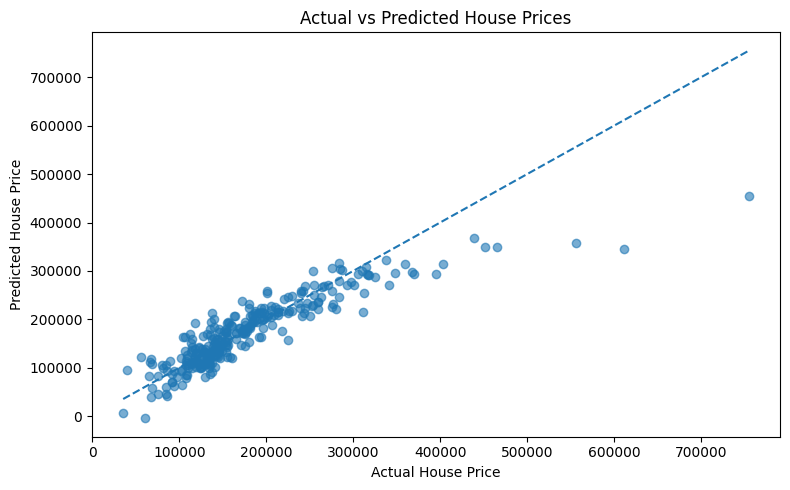

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()
